In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix)
from sklearn.preprocessing import StandardScaler

import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.utils import to_categorical

In [ ]:
import warnings
warnings.filterwarnings('ignore')

In [ ]:
df = pd.read_csv("seeds_new (1).csv")

In [ ]:
df=df.dropna(axis=1, how = "all")
df = df.loc[:, ~df.columns.str.startswith("Unnamed")]

In [ ]:
df.head()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
0,15.26,14.84,0.8710,5.763,3.312,2.221,5.220,1
1,14.88,14.57,0.8811,5.554,3.333,1.018,4.956,1
2,14.29,14.09,0.9050,5.291,3.337,2.699,4.825,1
3,13.84,13.94,0.8955,5.324,3.379,2.259,4.805,1
4,16.14,14.99,0.9034,5.658,3.562,1.355,5.175,1


In [ ]:
df.tail()

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
205,12.19,13.20,0.8783,5.137,2.981,3.631,4.870,3
206,11.23,12.88,0.8511,5.140,2.795,4.325,5.003,3
207,13.20,13.66,0.8883,5.236,3.232,8.315,5.056,3
208,11.84,13.21,0.8521,5.175,2.836,3.598,5.044,3
209,12.30,13.34,0.8684,5.243,2.974,5.637,5.063,3


In [ ]:
df.describe(
)

,Area,Perimeter,Compactness,Length of kernel,Width of kernel,Asymmetry coefficient,Length of kernel groove,"Class (1, 2, 3)"
count,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000,210.000000
mean,14.847524,14.559286,0.870999,5.628533,3.258605,3.700201,5.408071,2.000000
std,2.909699,1.305959,0.023629,0.443063,0.377714,1.503557,0.491480,0.818448
min,10.590000,12.410000,0.808100,4.899000,2.630000,0.765100,4.519000,1.000000
25%,12.270000,13.450000,0.856900,5.262250,2.944000,2.561500,5.045000,1.000000
50%,14.355000,14.320000,0.873450,5.523500,3.237000,3.599000,5.223000,2.000000
75%,17.305000,15.715000,0.887775,5.979750,3.561750,4.768750,5.877000,3.000000
max,21.180000,17.250000,0.918300,6.675000,4.033000,8.456000,6.550000,3.000000


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 210 entries, 0 to 209
Data columns (total 8 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   Area                     210 non-null    float64
 1   Perimeter                210 non-null    float64
 2   Compactness              210 non-null    float64
 3   Length of kernel         210 non-null    float64
 4   Width of kernel          210 non-null    float64
 5   Asymmetry coefficient    210 non-null    float64
 6   Length of kernel groove  210 non-null    float64
 7   Class (1, 2, 3)          210 non-null    int64  
dtypes: float64(7), int64(1)
memory usage: 13.3 KB


In [ ]:
df.shape

(210, 8)

In [ ]:
df.columns

Index(['Area', 'Perimeter', 'Compactness', 'Length of kernel',
       'Width of kernel', 'Asymmetry coefficient', 'Length of kernel groove',
       'Class (1, 2, 3)'],
      dtype='object')

In [ ]:
df.dtypes

,0
Area,float64
Perimeter,float64
Compactness,float64
Length of kernel,float64
Width of kernel,float64
Asymmetry coefficient,float64
Length of kernel groove,float64
"Class (1, 2, 3)",int64


In [ ]:
df.isnull().sum()

,0
Area,0
Perimeter,0
Compactness,0
Length of kernel,0
Width of kernel,0
Asymmetry coefficient,0
Length of kernel groove,0
"Class (1, 2, 3)",0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
X = df.drop("Class (1, 2, 3)", axis=1)
y_original = df['Class (1, 2, 3)']

print("Input shape:", X.shape)
print("Target shape:", y_original.shape)

Input shape: (210, 7)
Target shape: (210,)


In [ ]:
y = y_original - 1

print("original classes: ")
print(sorted(y_original.unique()))
print("ann encoded classes ")
print(sorted(y.unique()))

original classes: 
[np.int64(1), np.int64(2), np.int64(3)]
ann encoded classes 
[np.int64(0), np.int64(1), np.int64(2)]


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42,stratify = y)

print("X_train shape:", X_train.shape)
print("X_test_scaled shape:", X_test.shape)

X_train shape: (168, 7)
X_test_scaled shape: (42, 7)


In [ ]:
model = Sequential([
    Input(shape=(7,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(3, activation='softmax')
])

In [ ]:
model.summary()

Model: "sequential_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_3 (Dense)                 │ (None, 16)             │           128 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 8)              │           136 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 3)              │            27 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 291 (1.14 KB)

 Trainable params: 291 (1.14 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='sparse_categorical_crossentropy',
    metrics=['accuracy']
)

In [ ]:
loss = "sparse_categorical_crossentropy"

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

In [ ]:
history=model.fit(
    X_train,
    y_train,
    epochs=100,
    batch_size=16,
    validation_split=0.20,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.3433 - loss: 1.2591 - val_accuracy: 0.2353 - val_loss: 1.2092
Epoch 2/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4478 - loss: 1.0854 - val_accuracy: 0.5294 - val_loss: 1.0313
Epoch 3/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.5597 - loss: 0.9982 - val_accuracy: 0.6471 - val_loss: 0.9870
Epoch 4/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - accuracy: 0.7388 - loss: 0.9535 - val_accuracy: 0.8235 - val_loss: 0.9414
Epoch 5/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.7463 - loss: 0.9124 - val_accuracy: 0.7647 - val_loss: 0.8840
Epoch 6/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - accuracy: 0.7985 - loss: 0.8629 - val_accuracy: 0.7941 - val_loss: 0.8716
Epoch 7/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8955 - loss: 0.8234 - val_accuracy: 0.8235 - val_loss: 0.8312
Epoch 8/100
9/9 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - accuracy: 0.8358 - loss: 0.7936 - val_accuracy: 0.8235 - val_loss:

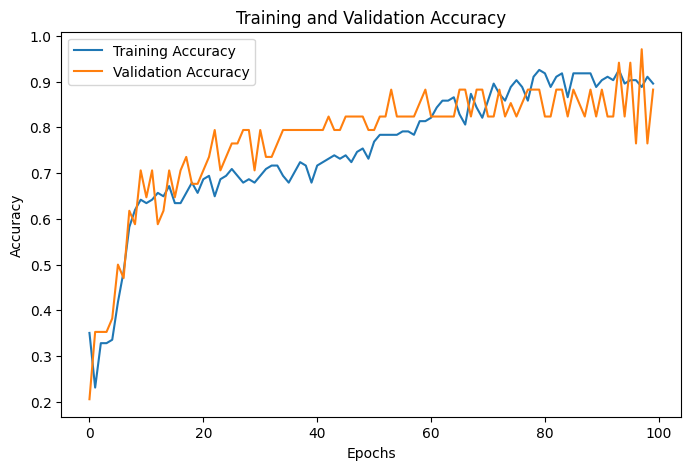

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['accuracy'], label='Training Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.title('Training and Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.show()

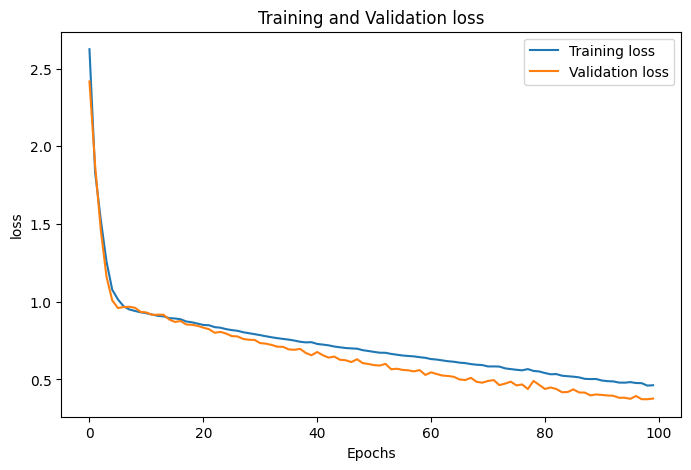

In [ ]:
plt.figure(figsize=(8,5))

plt.plot(history.history['loss'], label='Training loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Training and Validation loss')
plt.xlabel('Epochs')
plt.ylabel('loss')
plt.legend()
plt.show()

In [ ]:
test_loss, test_accuracy = model.evaluate(X_test, y_test)
print("TEST ACCURACY", test_accuracy)
print("TEST LOSS", test_loss)

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step - accuracy: 0.8810 - loss: 0.4531
TEST ACCURACY 0.8809523582458496
TEST LOSS 0.4531387984752655


In [ ]:
y_prob = model.predict(X_test, verbose = 1)
print(y_prob[:5])

2/2 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
[[0.5065915  0.4526121  0.04079638]
 [0.27299184 0.08814432 0.63886386]
 [0.55303335 0.41032213 0.03664449]
 [0.05811691 0.02618105 0.91570204]
 [0.21599129 0.7824964  0.00151226]]


In [ ]:
y_pred = np.argmax(y_prob, axis=1)

print("predicted encoded class")
print(y_pred[:10])

predicted encoded class
[0 2 0 2 1 2 1 1 1 1]


In [ ]:
y_pred_original = y_pred +1
y_test_original = y_test +1

print("predicted original class")
print(y_pred_original[:10])


predicted original class
[1 3 1 3 2 3 2 2 2 2]


In [ ]:
comparison = pd.DataFrame({'Actual': y_test_original, 'Predicted': y_pred_original})
comparison.head(15)

,Actual,Predicted
2,1,1
167,3,3
137,2,1
175,3,3
130,2,2
141,3,3
114,2,2
51,1,2
84,2,2
110,2,2


In [ ]:
accuracy = accuracy_score(y_test_original, y_pred_original)

print("Accuracy:", accuracy)


Accuracy: 0.8809523809523809


In [ ]:
recall = recall_score(y_test_original, y_pred_original, average='weighted')

print("recall:", recall)

recall: 0.8809523809523809


In [ ]:
precision = precision_score(y_test_original, y_pred_original, average='weighted')

print("Precision:", precision)

Precision: 0.8862179487179487


In [ ]:
f1 = f1_score(y_test_original, y_pred_original, average='weighted')

print("f1:", f1)


f1: 0.8814814814814814


In [ ]:
print(classification_report(y_test_original, y_pred_original))

              precision    recall  f1-score   support

           1       0.85      0.79      0.81        14
           2       0.81      0.93      0.87        14
           3       1.00      0.93      0.96        14

    accuracy                           0.88        42
   macro avg       0.89      0.88      0.88        42
weighted avg       0.89      0.88      0.88        42



In [ ]:
cm = confusion_matrix(y_test_original, y_pred_original)
print(cm)

[[11  3  0]
 [ 1 13  0]
 [ 1  0 13]]
